In [2]:
import os
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import matplotlib
# matplotlib.use("Agg")   # если запускаете без GUI / на сервере; иначе можно убрать
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# 1. Основные настройки
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 0.001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# НАСТРОЙТЕ ПУТИ К ВАШИМ ПАПКАМ
TRAIN_DIR = "./dataset/train"           # Папка со всеми картинками обучения
TEST_DIR = "./dataset/test"             # Папка со всеми картинками теста
CSV_PATH = "./dataset/train.csv"   # Исходный файл разметки (с шапкой file_name,class)

# Строгий алфавитный порядок классов
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer']
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(CLASS_NAMES)}

# ПУТЬ К ЭТАЛОННОМУ ФАЙЛУ
REFERENCE_SUBMIT = "./_yandex_submit_cv1.csv"   # положите рядом с main.py

# Загружаем эталонный порядок
ref_names = pd.read_csv(REFERENCE_SUBMIT, header=None)[0].tolist()
print(f"Эталонных строк: {len(ref_names)}")


Эталонных строк: 2424


In [4]:
# 2. Датасеты
class TrainDatasetFromCSV(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = row['file_name']
        label_name = row['class']
        
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
            
        return image, CLASS_TO_IDX[label_name]

import re

# Универсальная функция сортировки строк (работает одинаково на Linux и Windows)
def natural_sort_key(s):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]


class TestDatasetFromFolder(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        # Сортируем строго по универсальному ключу, независимо от операционной системы
        self.all_imgs = sorted(os.listdir(img_dir), key=natural_sort_key)

    def __len__(self):
        return len(self.all_imgs)

    def __getitem__(self, idx):
        img_name = self.all_imgs[idx]
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, img_name


In [5]:
# 3. Аугментация для повышения точности (чтобы пройти порог)
train_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(), # Случайное отражение помогает обобщению
    transforms.RandomRotation(10),     # Небольшой поворот
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [6]:
# 4. Архитектура модели (CNN с нуля, без предобученных весов)
class OptimizedCNN(nn.Module):
    def __init__(self):
        super(OptimizedCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 16x16
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 8x8
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.4), # Защита от переобучения
            nn.Linear(512, 5)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [7]:
# Загрузка данных с разделением на train/val для контроля точности
print(f"Используемое устройство: {DEVICE}")
full_train_dataset = TrainDatasetFromCSV(csv_file=CSV_PATH, img_dir=TRAIN_DIR, transform=train_transforms)
train_size = int(0.85 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_data, val_data = torch.utils.data.random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

test_dataset = TestDatasetFromFolder(img_dir=TEST_DIR, transform=test_transforms)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = OptimizedCNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

train_losses, val_losses, val_accs = [], [], []

Используемое устройство: cpu


In [8]:
# Цикл обучения
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        
    # Валидация для проверки точности
    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    train_losses.append(train_loss / train_size)
    val_losses.append(val_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Эпоха {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_losses[-1]:.4f} | "
          f"Val Loss: {val_losses[-1]:.4f} | "
          f"Val Acc: {val_accs[-1]:.2f}%")


Эпоха 1/50 | Train Loss: 1.5064 | Val Loss: 1.1691 | Val Acc: 50.27%
Эпоха 2/50 | Train Loss: 1.1143 | Val Loss: 1.0894 | Val Acc: 52.80%
Эпоха 3/50 | Train Loss: 1.0697 | Val Loss: 1.1096 | Val Acc: 54.40%
Эпоха 4/50 | Train Loss: 1.0044 | Val Loss: 1.0482 | Val Acc: 56.00%
Эпоха 5/50 | Train Loss: 0.9829 | Val Loss: 0.9710 | Val Acc: 60.13%
Эпоха 6/50 | Train Loss: 0.9406 | Val Loss: 0.9930 | Val Acc: 59.73%
Эпоха 7/50 | Train Loss: 0.8921 | Val Loss: 0.9762 | Val Acc: 61.07%
Эпоха 8/50 | Train Loss: 0.8804 | Val Loss: 1.0588 | Val Acc: 55.47%
Эпоха 9/50 | Train Loss: 0.8605 | Val Loss: 0.9111 | Val Acc: 61.73%
Эпоха 10/50 | Train Loss: 0.8035 | Val Loss: 0.9263 | Val Acc: 61.47%
Эпоха 11/50 | Train Loss: 0.7851 | Val Loss: 0.8820 | Val Acc: 64.13%
Эпоха 12/50 | Train Loss: 0.7711 | Val Loss: 0.9562 | Val Acc: 62.40%
Эпоха 13/50 | Train Loss: 0.7406 | Val Loss: 0.9030 | Val Acc: 64.67%
Эпоха 14/50 | Train Loss: 0.7266 | Val Loss: 0.8793 | Val Acc: 64.13%
Эпоха 15/50 | Train Loss: 0.7

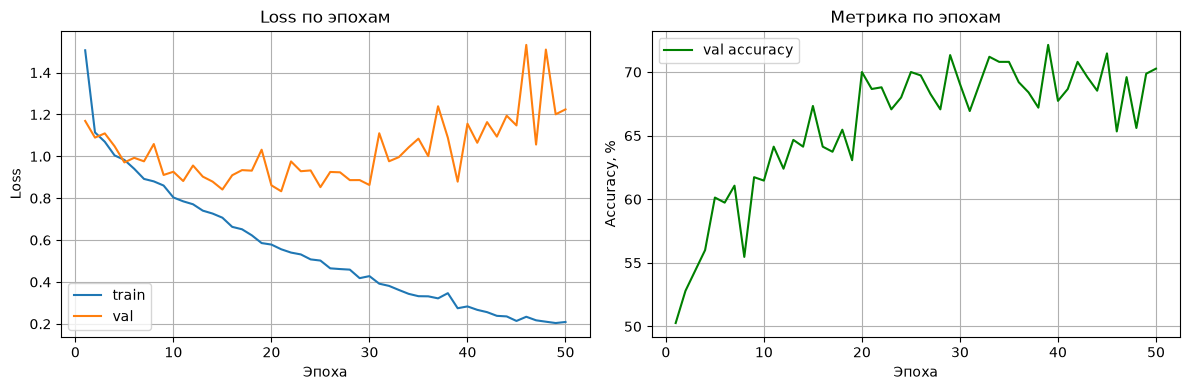

Графики сохранены в training_curves.png


In [9]:
# Графики
epochs_range = range(1, len(train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_losses, label="train")
axes[0].plot(epochs_range, val_losses, label="val")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss по эпохам")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, val_accs, color="green", label="val accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy, %")
axes[1].set_title("Метрика по эпохам")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()
print("Графики сохранены в training_curves.png")

In [10]:
# 6. Предсказание для теста и сохранение
print("\nГенерация предсказаний...")
model.eval()
submission_results = []

with torch.no_grad():
    for images, filenames in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        for filename, pred_idx in zip(filenames, preds):
            pred_label = CLASS_NAMES[pred_idx.item()]
            submission_results.append([filename, pred_label])

# Сохраняем СТРОГО без заголовков и индексов
df_out = pd.DataFrame(submission_results)
# df_out.to_csv("submission.csv", index=False, header=False, encoding='utf-8')
# print("Файл 'submission.csv' успешно создан. Отправляйте его на платформу!")

# После предсказаний: собираем словарь filename -> label
pred_by_name = {fname: pred_label for fname, pred_label in submission_results}

# Проверяем, что все файлы из эталона предсказаны
missing = [n for n in ref_names if n not in pred_by_name]
assert not missing, f"Не предсказаны: {missing[:5]}"

# Сохраняем в порядке эталона
with open("submission.csv", "w", encoding="utf-8", newline="\n") as f:
    for fname in ref_names:
        f.write(f"{fname},{pred_by_name[fname]}\n")

print("submission.csv сохранён в порядке эталона")



Генерация предсказаний...
submission.csv сохранён в порядке эталона
